In [1]:
from pathlib import Path
import pandas as pd
import pyarrow.dataset as ds

In [2]:
DATA_DIR = Path("data")
df = pd.read_parquet("../data/films_merged.parquet")

# Pour pouvoir faire des analyses de données, on transforme les données de la colonne "averageRating_IMDb" en nombres
df["averageRating_IMDb"] = pd.to_numeric(
    df["averageRating_IMDb"],
    errors="coerce"
)

Intercept : [6.19695404]
Coefficient : [3.12667791e-09]
R² : 0.00406875431370235


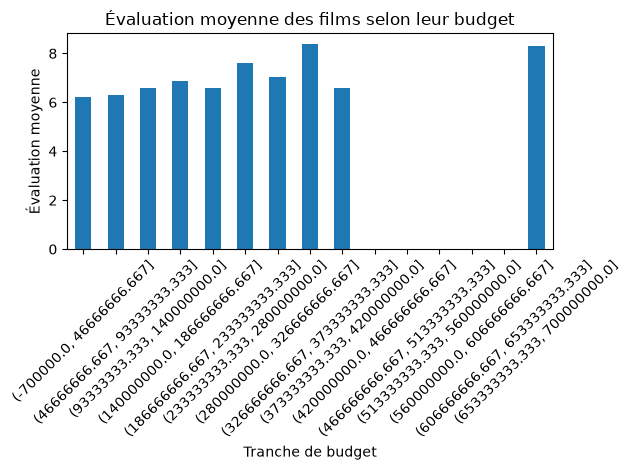

In [3]:
from sklearn.linear_model import LinearRegression
import matplotlib.pyplot as plt


df_reg = df.dropna(subset = ["averageRating_IMDb", "budget"])
y = df_reg[["averageRating_IMDb"]]
X = df_reg[["budget"]]
modele = LinearRegression()
modele.fit(X, y)

print("Intercept :", modele.intercept_)
print("Coefficient :", modele.coef_[0])
print("R² :", modele.score(X, y))

df_reg["tranche_budget"] = pd.cut(
    df_reg["budget"],
    bins=15
)


moyennes = df_reg.groupby(
    "tranche_budget",
    observed=False
)["averageRating_IMDb"].mean()

moyennes.plot(kind="bar")
plt.xlabel("Tranche de budget")
plt.ylabel("Évaluation moyenne")
plt.title("Évaluation moyenne des films selon leur budget")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

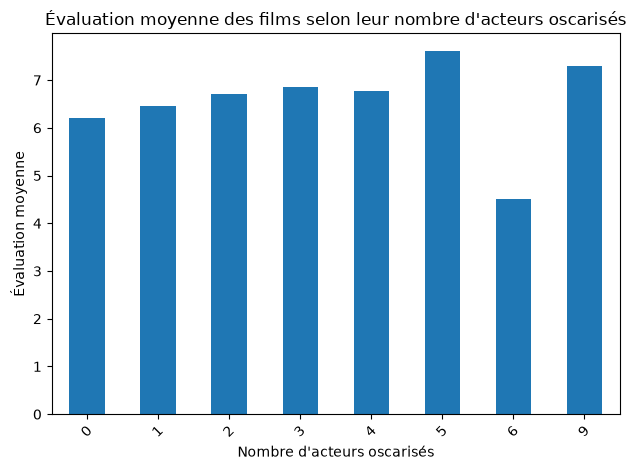

In [4]:
# On ajoute une colonne pour donner le nombre d'acteurs oscarisés dans les films

df_reg2 = df[df["release_date"] <= "2016-01-01"] # car la liste des oscars n'est plus à jour depuis 2016
df_reg2 = df_reg2.dropna(subset = ["principals_IMDb"])
df_acteurs_osc = pd.read_csv("../data/oscars.csv")

def compter_oscarises(liste_acteurs):

    n=0
    for acteur in liste_acteurs:

        if acteur in df_acteurs_osc["Name"].tolist():
            n += 1
    return n
    

df_reg2["nb_acteurs_oscarises"] = df_reg2["principals_IMDb"].apply(compter_oscarises)
df_reg2["acteur_oscarise"] = (df_reg2["nb_acteurs_oscarises"]>0) # 0 ou 1

moyennes_osc = df_reg2.groupby(
    "nb_acteurs_oscarises",
    observed=False
)["averageRating_IMDb"].mean()

moyennes_osc.plot(kind="bar")
plt.xlabel("Nombre d'acteurs oscarisés")
plt.ylabel("Évaluation moyenne")
plt.title("Évaluation moyenne des films selon leur nombre d'acteurs oscarisés")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


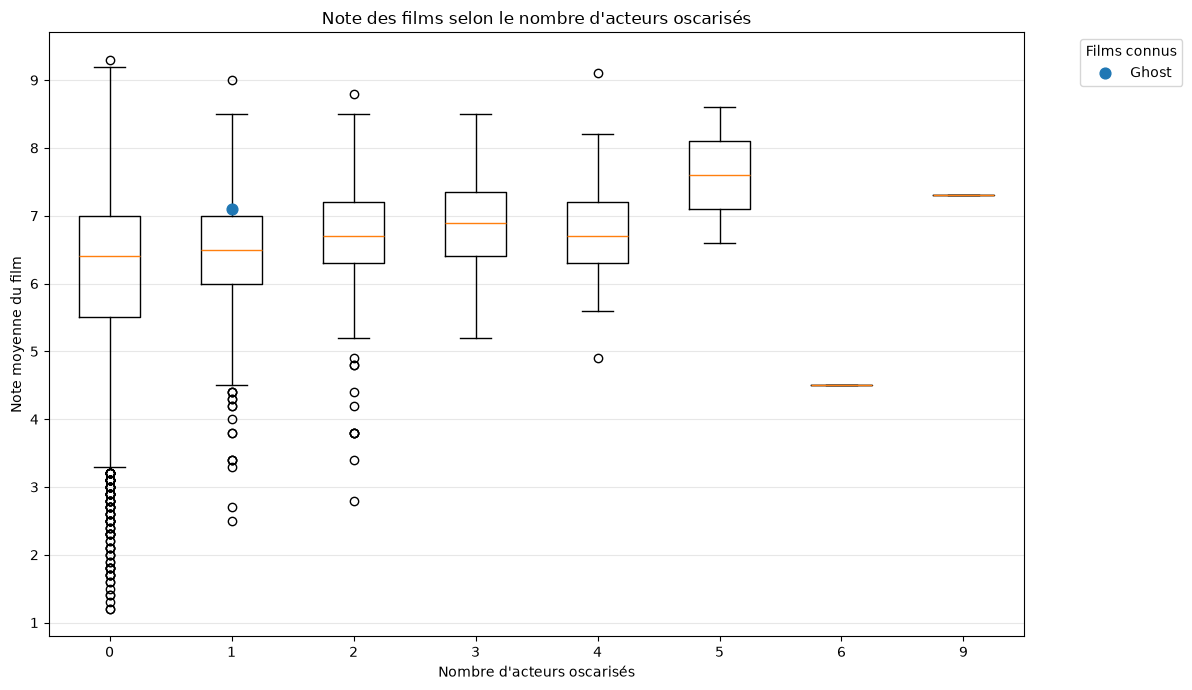

In [5]:
groupes = [
    groupe["averageRating_IMDb"].dropna().values
    for _, groupe in df_reg2.groupby("nb_acteurs_oscarises")
]

categories = sorted(df_reg2["nb_acteurs_oscarises"].dropna().unique())

plt.figure(figsize=(12, 7))
plt.boxplot(groupes, tick_labels=categories)

plt.xlabel("Nombre d'acteurs oscarisés")
plt.ylabel("Note moyenne du film")
plt.title("Note des films selon le nombre d'acteurs oscarisés")
plt.grid(axis="y", alpha=0.3)

liste_films_connus = [
    "Titanic", "Fight Club", "Casablanca",
    "Le Bon, la Brute et le Truand",
    "Le Fabuleux Destin d'Amélie Poulain",
    "Les Sept Samouraïs", "Ghost"
]

films_connus = df_reg2[df_reg2["title"].isin(liste_films_connus)]

# Palette de couleurs
couleurs = plt.cm.tab10.colors

# Ajouter chaque film individuellement
for i, (_, film) in enumerate(films_connus.iterrows()):

    x = categories.index(film["nb_acteurs_oscarises"]) + 1
    y = film["averageRating_IMDb"]

    plt.scatter(
        x, y,
        color=couleurs[i % len(couleurs)],
        s=60,
        zorder=3,
        label=film["title"]
    )

plt.legend(title="Films connus", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

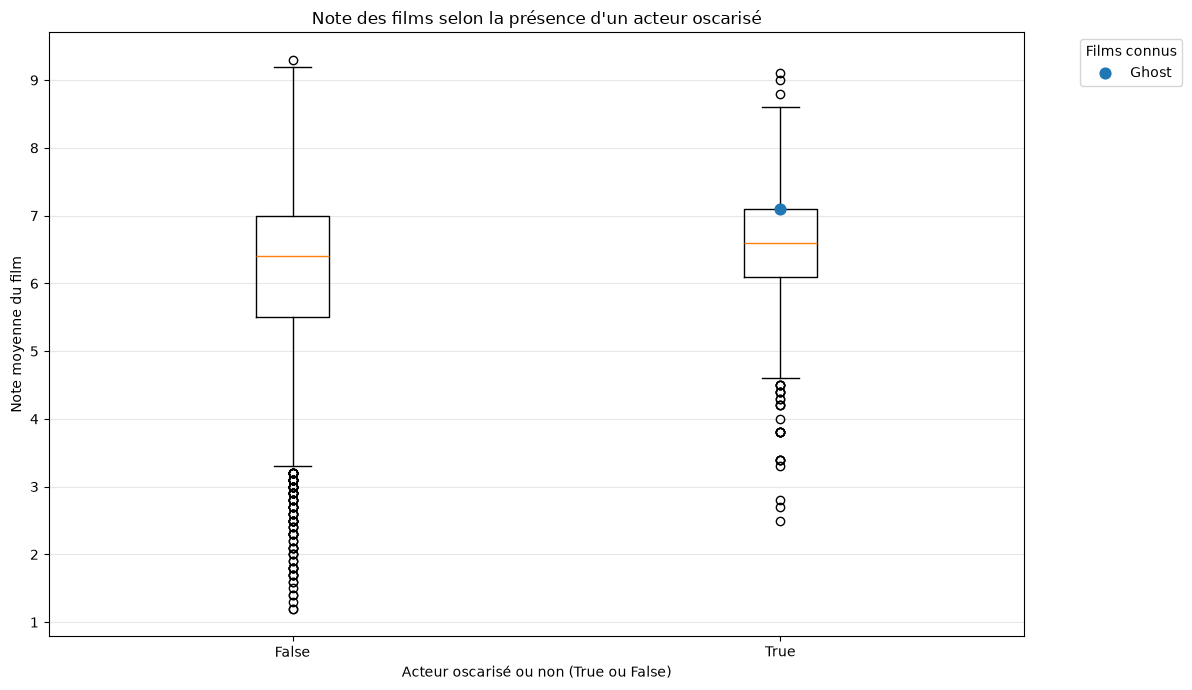

In [6]:
groupes = [
    groupe["averageRating_IMDb"].dropna().values
    for _, groupe in df_reg2.groupby("acteur_oscarise")
]

categories = sorted(df_reg2["acteur_oscarise"].dropna().unique())

plt.figure(figsize=(12, 7))
plt.boxplot(groupes, tick_labels=categories)

plt.xlabel("Acteur oscarisé ou non (True ou False)")
plt.ylabel("Note moyenne du film")
plt.title("Note des films selon la présence d'un acteur oscarisé")
plt.grid(axis="y", alpha=0.3)

liste_films_connus = [
    "Titanic", "Fight Club", "Casablanca",
    "Le Bon, la Brute et le Truand",
    "Le Fabuleux Destin d'Amélie Poulain",
    "Les Sept Samouraïs", "Ghost"
]

films_connus = df_reg2[df_reg2["title"].isin(liste_films_connus)]

# Palette de couleurs
couleurs = plt.cm.tab10.colors

# Ajouter chaque film individuellement
for i, (_, film) in enumerate(films_connus.iterrows()):

    x = categories.index(film["acteur_oscarise"]) + 1
    y = film["averageRating_IMDb"]

    plt.scatter(
        x, y,
        color=couleurs[i % len(couleurs)],
        s=60,
        zorder=3,
        label=film["title"]
    )

plt.legend(title="Films connus", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [7]:
import numpy as np

MIN_BUDGET = 10000
data = df_reg2[["id", "nb_acteurs_oscarises", "budget", "revenue"]].copy()
data = data[(data["budget"] >= MIN_BUDGET) & (data["revenue"] > 0)]
data["roi"] = data["revenue"] / data["budget"]
data["log_roi"] = np.log10(data["roi"])

In [8]:
#df_reg2.columns
#print(df_reg2["release_date"].dtype)
print(df_reg2["release_date"])

0       2015-02-20
1       2010-07-06
3       2012-10-17
4       1953-07-03
5       1972-06-21
           ...    
9992    2014-10-02
9994    2000-10-04
9996    2006-03-10
9998    1988-09-02
9999    1945-05-11
Name: release_date, Length: 6486, dtype: str


In [9]:
from Script.Analyse_oscars.py import note_oscar
note_oscar()

ModuleNotFoundError: No module named 'Script'